# Campaign Network Analysis - Clean Version
**Dataset:** 420 posts, 251 accounts, prayforkalimantan campaign

**Findings:** Data organik, bukan buzzer coordinated attack. Analisis fokus ke network structure & influencer identification.

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Config
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries loaded")

Libraries loaded


In [ ]:
df = pd.read_csv("../data/processed/prayforkalimantan/standardized_data.csv")df["date"] = pd.to_datetime(df["date"])# ID as stringfor col in ["account_id", "post_id", "target_account_id", "target_post_id"]:    if col in df.columns:        df[col] = df[col].astype(str).replace("nan", pd.NA)print(f"Loaded: {len(df)} posts from {df['account_id'].nunique()} accounts")print(f"Date range: {df['date'].min()} to {df['date'].max()}")df.head()

Loaded: 420 posts from 251 accounts
Date range: 2026-10-05 16:18:44+00:00 to 2026-11-04 11:38:20+00:00


,post_id,account_id,id,user_id,source_post_id,source_account_id,target_post_id,target_account_id,target_username,relation_type,mentioned_user_ids,date,text,url,conversation_id,username,created,followers,following,statuses,bio,avatar,is_rt,is_reply,is_quote,isu,query,n_tags
0,2117944532226740610,2095858716981841921,2117944532226740610,2095858716981841921,2117944532226740610,2095858716981841921,2.1178977330090063e+18,2.0284230575059108e+18,naraeraa,quote,[],2026-11-04 11:38:20+00:00,#prayforkalimantan\n#PRAYFORPAPUA \nFor the fo...,https://x.com/Tenfuy/status/2117944532226740610,2117944532226740610,Tenfuy,2026-09-04 12:59:07+00:00,1,10,119,17prime🫯🇵🇸,https://pbs.twimg.com/profile_images/211331362...,False,False,True,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,2
1,2117897733009006713,2028423057505910784,2117897733009006713,2028423057505910784,2117897733009006713,2028423057505910784,<NA>,<NA>,NaN,original,[],2026-11-04 08:32:22+00:00,ALL EYES ON KALIMANTAN ❤️‍🔥❤️‍🔥❤️‍🔥 https://t....,https://x.com/naraeraa/status/2117897733009006713,2117897733009006713,naraeraa,2026-03-02 10:52:10+00:00,6168,4196,29273,24/7 in X ☺️\nJust a little girl with a big dr...,https://pbs.twimg.com/profile_images/210451635...,False,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,0
2,2117927960212865525,1546272513302208513,2117927960212865525,1546272513302208513,2117927960212865525,1546272513302208513,<NA>,<NA>,NaN,original,[],2026-11-04 10:32:29+00:00,#PRAYFORLAMPUNG\n#PRAYFORSULAWESI\n#PRAYFORKAL...,https://x.com/notnamern/status/211792796021286...,2117927960212865525,notnamern,2022-07-10 23:17:59+00:00,184,370,22761,🇵🇸 | ONLY SOLOIST HUANG RENJUN NINGNING TAEYEO...,https://pbs.twimg.com/profile_images/211684401...,False,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,15
3,2117922457629954389,903456043304239104,2117922457629954389,903456043304239104,2117922457629954389,903456043304239104,2.1178770020407544e+18,2.1055817789039447e+18,ccaramelh2h,quote,[],2026-11-04 10:10:37+00:00,Terus staff Pemprovnya kek gini\nCr : @/selasa...,https://x.com/akudanteh/status/211792245762995...,2117922457629954389,akudanteh,2017-09-01 03:14:40+00:00,505,4671,45605,This user has turned into an entity named Teh ...,https://pbs.twimg.com/profile_images/210779004...,False,False,True,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,12
4,2117877002040754390,2105581778903945216,2117877002040754390,2105581778903945216,2117877002040754390,2105581778903945216,<NA>,<NA>,NaN,original,[],2026-11-04 07:10:00+00:00,🚨Update Demo\nSamarinda Kaltim ✊🏼🇮🇩❤️‍🔥🔥\n\nRa...,https://x.com/ccaramelh2h/status/2117877002040...,2117877002040754390,ccaramelh2h,2026-10-01 08:54:12+00:00,4897,4562,18691,sending all the love to all of u guys 🩷,https://pbs.twimg.com/profile_images/211645076...,False,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,1


## 2. Feature Engineering

In [ ]:
df["hashtags"] = df["text"].str.findall(r"#\w+")
df["n_tags"] = df["hashtags"].str.len()

df["body_clean"] = df["text"].str.replace(r"^(@\w+\s*)+", "", regex=True).str.strip()
df["body_len"] = df["body_clean"].str.len()

df["has_url"] = df["text"].str.contains(r"https?://", regex=True)

print("Features extracted:")
print(df[["n_tags", "body_len", "has_url"]].describe())

Features extracted:
           n_tags     body_len
count  420.000000   420.000000
mean     5.380952   229.335714
std      5.152808   256.097524
min      0.000000    18.000000
25%      1.000000   132.750000
50%      3.000000   211.000000
75%     10.000000   258.250000
max     15.000000  2385.000000


## 3. Account-Level Analysis

In [ ]:
accounts = df.groupby("account_id").agg(
    username=("username", "first"),
    n_posts=("post_id", "count"),
    avg_tags=("n_tags", "mean"),
    avg_body_len=("body_len", "mean"),
    n_replies=("is_reply", "sum"),
    n_quotes=("is_quote", "sum"),
    n_originals=("relation_type", lambda x: (x == "original").sum()),
    first_post=("date", "min"),
    last_post=("date", "max"),
    followers=("followers", "first"),
    following=("following", "first")
).reset_index()

accounts["active_hours"] = (accounts["last_post"] - accounts["first_post"]).dt.total_seconds() / 3600
accounts["post_rate"] = accounts["n_posts"] / (accounts["active_hours"] + 0.1)

print(f"Total accounts: {len(accounts)}")
accounts.describe()

Total accounts: 251


,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,followers,following,active_hours,post_rate
count,251.000000,251.000000,251.000000,251.000000,251.000000,251.000000,2.510000e+02,251.000000,251.000000,251.000000
mean,1.673307,5.132769,195.345924,0.171315,0.382470,1.119522,1.913932e+05,1940.223108,26.108913,8.512802
std,2.404339,5.021918,146.978584,0.454460,0.961838,2.051745,2.677020e+06,3395.875790,91.816269,3.982746
min,1.000000,0.000000,18.000000,0.000000,0.000000,0.000000,1.000000e+00,1.000000,0.000000,0.003958
25%,1.000000,1.000000,120.500000,0.000000,0.000000,0.000000,1.770000e+02,169.000000,0.000000,10.000000
50%,1.000000,2.750000,201.000000,0.000000,0.000000,1.000000,1.012000e+03,593.000000,0.000000,10.000000
75%,1.000000,10.000000,247.500000,0.000000,0.000000,1.000000,5.159500e+03,2208.500000,0.000000,10.000000
max,23.000000,15.000000,2002.000000,3.000000,8.000000,22.000000,4.235188e+07,22560.000000,575.533611,27.692308


In [ ]:
influencers = accounts[
    (accounts["n_posts"] >= 10) | 
    ((accounts["followers"] > 1000) & (accounts["n_posts"] >= 5))
].sort_values("n_posts", ascending=False)

print(f"Influencers: {len(influencers)}")
print(influencers[["username", "n_posts", "avg_tags", "followers", "post_rate"]].head(10))

Influencers: 10
            username  n_posts   avg_tags  followers  post_rate
207     Babyypinkeuu       23  12.391304       2270   0.052648
143      jenostalker       22   5.681818       8538   0.042544
111  ABjodohComeback       14   0.857143       3603   0.048436
191  komisarisnetzen       11   0.909091       7378   0.064837
71       serabutannn        8   1.250000      17640   0.053163
230       ejaaipongg        7   1.285714      23431   0.060936
78     whiterosestea        5   1.400000       6087   0.010436
100    PutriKariimah        5   1.800000       7770   0.017224
126        awikuchuz        5   1.200000       4003   0.144337
146    syahfafa99983        5   2.800000       4321   0.042562


## 4. Network Analysis

In [ ]:
edges = df[df["relation_type"].isin(["reply", "quote"])]
edges = edges[["account_id", "username", "target_account_id", "target_username", "relation_type"]].dropna(subset=["target_account_id"])

G = nx.from_pandas_edgelist(
    edges, "account_id", "target_account_id",
    edge_attr=["relation_type"], create_using=nx.DiGraph()
)

print(f"Network: {len(G.nodes())} nodes, {len(G.edges())} edges")
print(f"Density: {nx.density(G):.4f}")

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pagerank = nx.pagerank(G)

username_map = df[["account_id", "username"]].drop_duplicates().set_index("account_id")["username"].to_dict()
target_username_map = edges[["target_account_id", "target_username"]].drop_duplicates().set_index("target_account_id")["target_username"].to_dict()
username_map.update(target_username_map)

accounts["in_degree"] = accounts["account_id"].map(in_deg).fillna(0)
accounts["out_degree"] = accounts["account_id"].map(out_deg).fillna(0)
accounts["pagerank"] = accounts["account_id"].map(pagerank).fillna(0)

print("\n=== HIGH TARGETS (>5 mentions) ===")
high_targets = [(n, in_deg[n], username_map.get(n, str(n)[-8:])) for n in G.nodes() if in_deg[n] > 5]
high_targets.sort(key=lambda x: x[1], reverse=True)
for acc_id, deg, username in high_targets:
    print(f"@{username}: {deg} mentions")

print("\n=== HIGH ENGAGERS (>5 replies/quotes) ===")
high_engagers = [(n, out_deg[n], username_map.get(n, str(n)[-8:])) for n in G.nodes() if out_deg[n] > 5]
high_engagers.sort(key=lambda x: x[1], reverse=True)
for acc_id, deg, username in high_engagers:
    print(f"@{username}: {deg} interactions")

Network: 168 nodes, 121 edges
Density: 0.0043

=== HIGH TARGETS (>5 mentions) ===
@Babyypinkeuu: 26 mentions

=== HIGH ENGAGERS (>5 replies/quotes) ===
@akudanteh: 8 interactions


## 5. Network Visualization

Saved: output/campaign_network.png


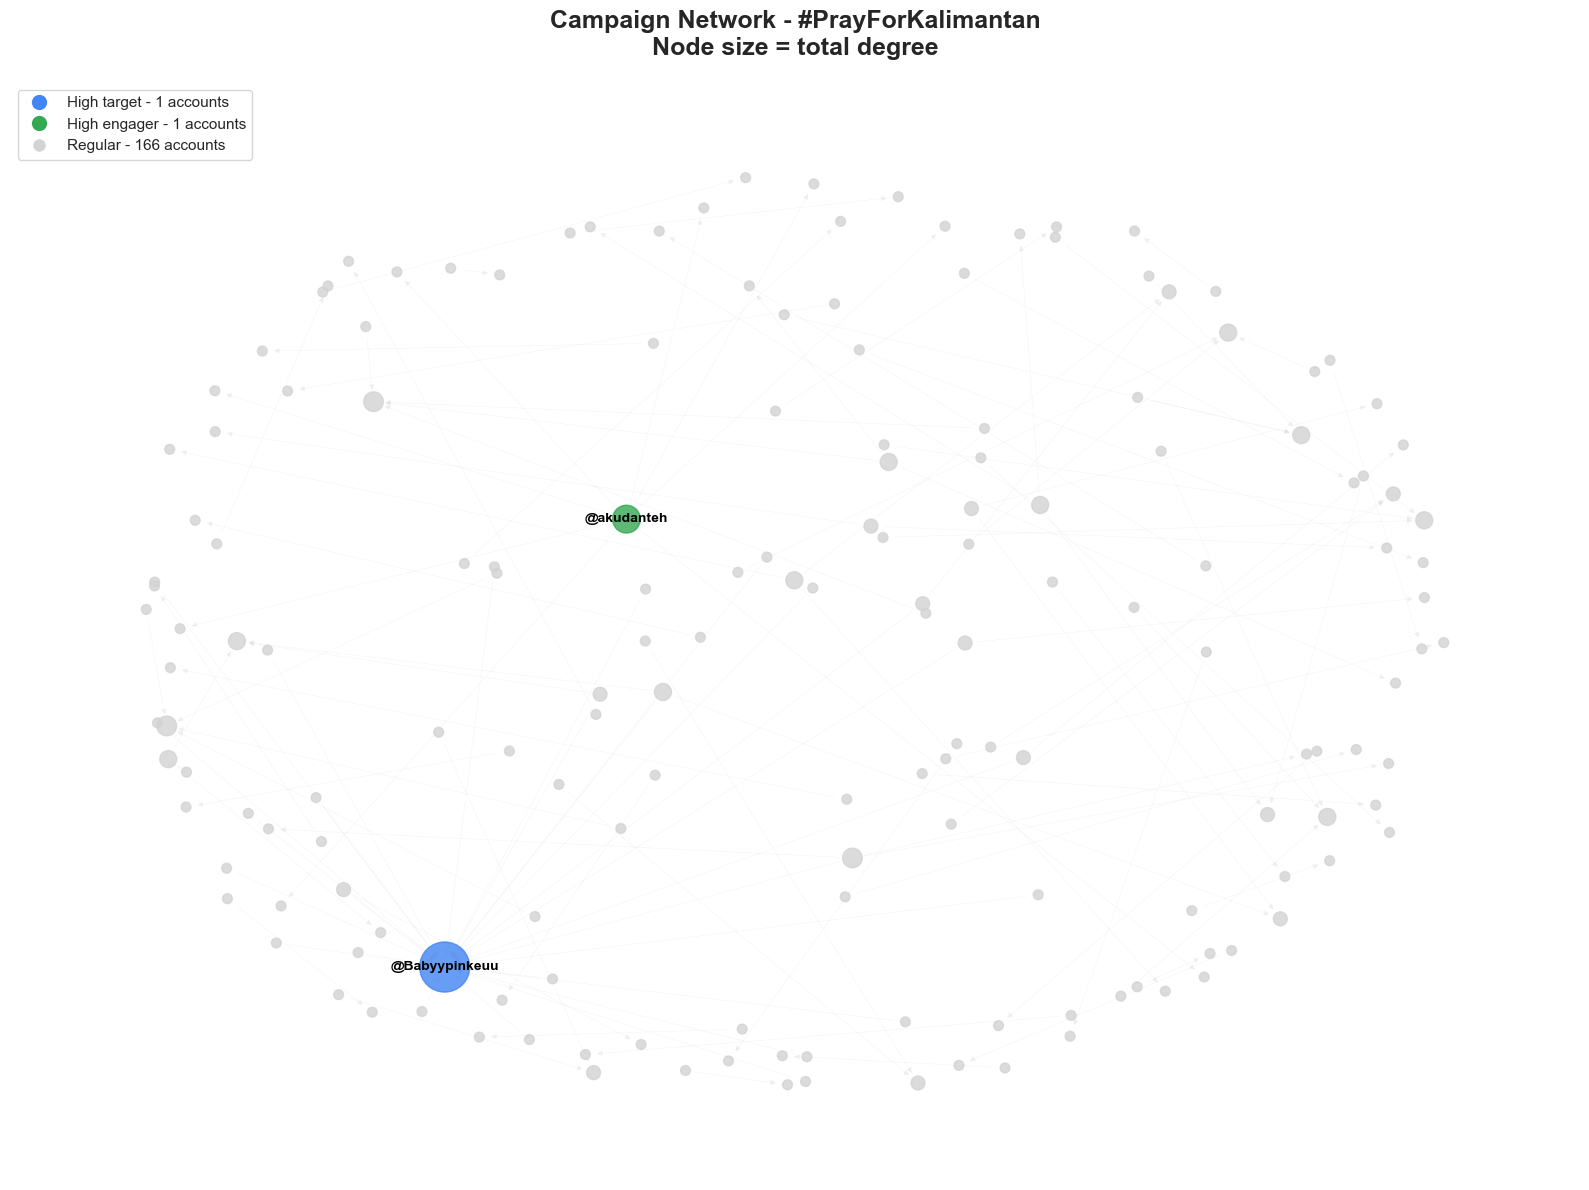

In [ ]:
node_colors = []
for n in G.nodes():
    if in_deg[n] > 5:  # High target
        node_colors.append("#4285f4")  
    elif out_deg[n] > 5:  # High engager
        node_colors.append("#34a853") 
    else:
        node_colors.append("#d3d3d3")  

node_sizes = [max(50, (in_deg[n] + out_deg[n]) * 50) for n in G.nodes()]

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(G, pos, edge_color="lightgray", 
                       arrows=True, arrowsize=8, width=0.3, alpha=0.3, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, 
                       node_size=node_sizes, alpha=0.8, ax=ax)

important = [n for n in G.nodes() if in_deg[n] > 5 or out_deg[n] > 5]
labels = {n: f"@{username_map.get(n, str(n)[-8:])}" for n in important}
nx.draw_networkx_labels(G, pos, labels, font_size=10, font_weight="bold", ax=ax)

from matplotlib.lines import Line2D
legend = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4285f4', 
           markersize=12, label=f'High target - {len([n for n in G.nodes() if in_deg[n] > 5])} accounts'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#34a853', 
           markersize=12, label=f'High engager - {len([n for n in G.nodes() if out_deg[n] > 5])} accounts'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgray', 
           markersize=10, label=f'Regular - {len([n for n in G.nodes() if in_deg[n] <= 5 and out_deg[n] <= 5])} accounts')
]
ax.legend(handles=legend, loc='upper left', fontsize=11)
ax.set_title("Campaign Network - #PrayForKalimantan\nNode size = total degree", 
             fontsize=18, fontweight='bold', pad=20)
ax.axis('off')

import os
os.makedirs("../output", exist_ok=True)
plt.tight_layout()
plt.savefig("../output/campaign_network.png", dpi=200, bbox_inches="tight", facecolor='white')
print("Saved: output/campaign_network.png")
plt.show()

## 6. Temporal Analysis

Saved: output/temporal_activity.png


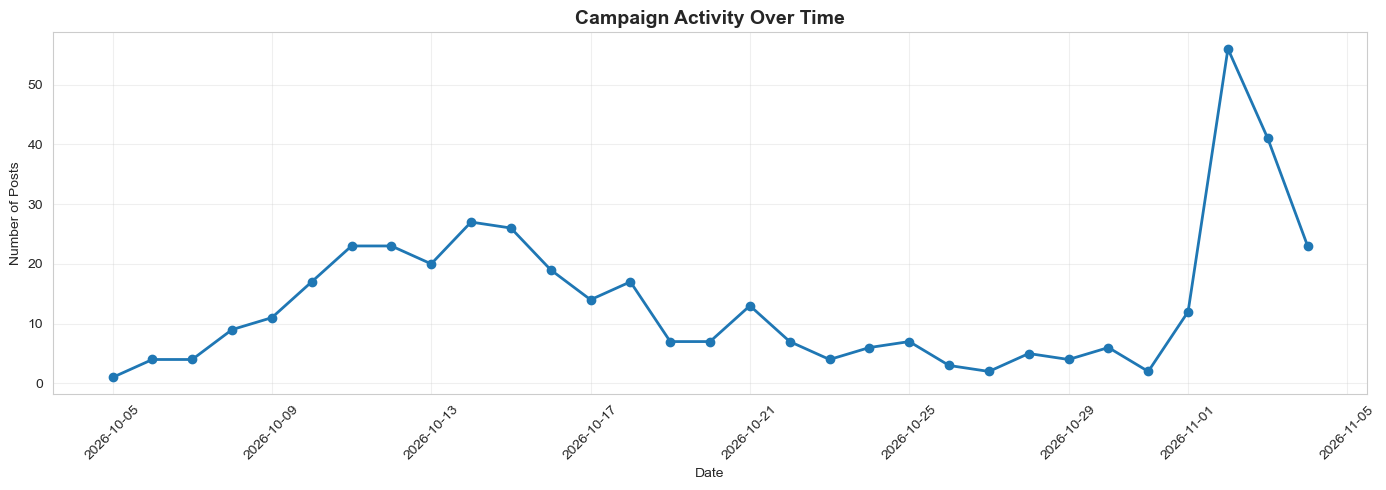

In [ ]:
df["date_only"] = df["date"].dt.date
daily = df.groupby("date_only").size().reset_index(name="n_posts")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["date_only"], daily["n_posts"], marker='o', linewidth=2)
ax.set_title("Campaign Activity Over Time", fontsize=14, fontweight='bold')
ax.set_xlabel("Date")
ax.set_ylabel("Number of Posts")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../output/temporal_activity.png", dpi=150, bbox_inches="tight")
print("Saved: output/temporal_activity.png")
plt.show()

## 7. Export Results

In [9]:
import os
os.makedirs("../data/features", exist_ok=True)
os.makedirs("../output", exist_ok=True)

# Save features
df.to_csv("../data/features/posts_with_features.csv", index=False)
accounts.to_csv("../data/features/account_features.csv", index=False)

print("Saved:")
print("  - data/features/posts_with_features.csv")
print("  - data/features/account_features.csv")
print("\nNext step: Text embedding with IndoBERTweet (notebook 03)")

Saved:
  - data/features/posts_with_features.csv
  - data/features/account_features.csv

Next step: Text embedding with IndoBERTweet (notebook 03)
